In [131]:
import numpy as np
import matplotlib.pyplot as plt

In [132]:
def RungeKutta32(
        x_init : float,
        x_end : float,
        y_init : np.ndarray[np.float64],
        f,
        h0 : float =0.1,
        tol : float = 0.001,
        alpha : float = 0.8
                 ) -> tuple:
    
    x  =  np.zeros(int(np.ceil((x_end-x_init)/h0)))
    y  =  np.zeros((int(np.ceil((x_end-x_init)/h0)),len(y_init)))
    h  =  h0
    x[0] = x_init
    y[0] = y_init
    z = 0

    n  =  0
    k1  =  f(x_init,y_init)

    while x_end-x[n]>0:
       

        # Gjør arrayet større i tilfellet at gjetningen på størreslen var for liten
        if len(x)==n+1:
            
            sizeInc=int(np.ceil((x_end-x[n])/h))
            x=np.concatenate((x,np.zeros(sizeInc)))
            y=np.concatenate((y,np.zeros((sizeInc,len(y_init)))))

        
        h = min(h,x_end-x[n])
        k2 = f(x[n]+h/2,y[n]+h*k1/2)
        k3 = f(x[n]+3/4*h,y[n]+3/4*h*k2)
        y[n+1] = (y[n]+h/9*(2*k1+3*k2+4*k3))
        x[n+1] = (x[n]+h)
        k4 = f(x[n]+h,y[n+1])
        z = y[n]+h/24*(7*k1+6*k2+8*k3+3*k4)
        err_est = np.linalg.norm(y[n+1]-z)
        if err_est<tol:
            n += 1
            k1 = k4
        h=alpha*h*(tol/err_est)**(1/3)
    
    # Fjerner nuller bakerst i arrayet i tilfellet array ble for stort
    x = np.trim_zeros(x,trim="b")
    y = np.trim_zeros(y,trim="b")


    return x, y, n

In [133]:
def diff_func_1a(
        x : float,
        y : np.ndarray[np.float64]
    )  -> np.ndarray[np.float64]:

    out=np.zeros_like(y)

    out[0]=y[1]
    out[1]=-4*np.sin(2*x)

    return out

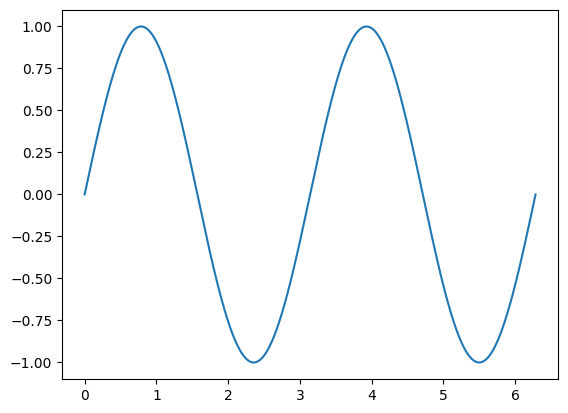

In [134]:
x_init = 0
x_end = 2*np.pi
y_init = np.array([0,2])
h0 = 0.1

x , y , n= RungeKutta32(x_init,x_end,y_init,diff_func_1a,h0,tol= 1e-7, alpha=0.8)


plt.figure("Oppgave 1c")
plt.plot(x,y[:,0])


In [135]:
def anal_solution(x):
    return np.sin(2*x)


In [136]:
tols= np.logspace(1,-8,100)
error= np.zeros_like(tols)


for i in range(len(tols)):
    x , y , n= RungeKutta32(x_init,x_end,y_init,diff_func_1a,h0,tol = tols[i], alpha=0.8)
    
    error[i] = np.linalg.norm(y[:,0]-anal_solution(x))

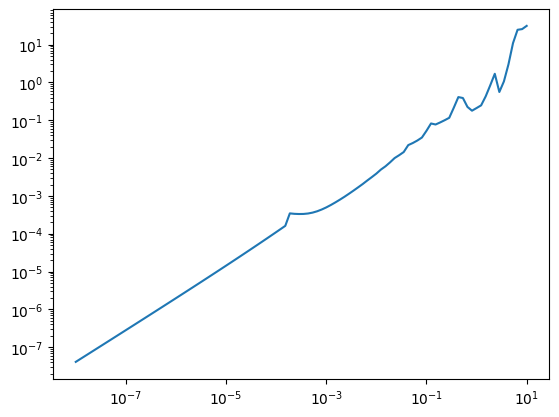

In [137]:
plt.figure("Error/tols")
plt.plot(tols,error)
plt.xscale("log")
plt.yscale("log")

In [138]:
alphas= np.linspace(0.1,1,100)
Iterations = np.zeros_like(alphas)
for i in range(len(alphas)):
    x , y , n= RungeKutta32(x_init,x_end,y_init,diff_func_1a,h0, alpha=alphas[i])
    Iterations[i] = n

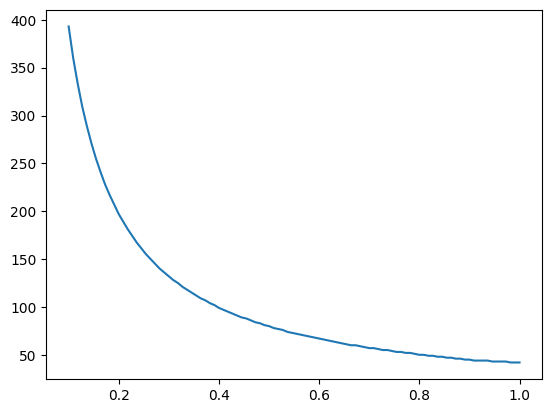

In [139]:
plt.figure("Iterations/alphas")
plt.plot(alphas, Iterations)

In [140]:
def sekantMetode(
        g, 
        z0 : float,
        z1 : float,
        tol : float,
) -> float:
    z = [z0,z1]
    i=1
    while abs(z[i]-z[i-1])>tol:
        z_new=(z[i-1]*g(z[i])-z[i]*g(z[i-1]))/(g(z[i])-g(z[i-1]))
        z.append(z_new)
        i+=1
    return z


-0.45653942611523535


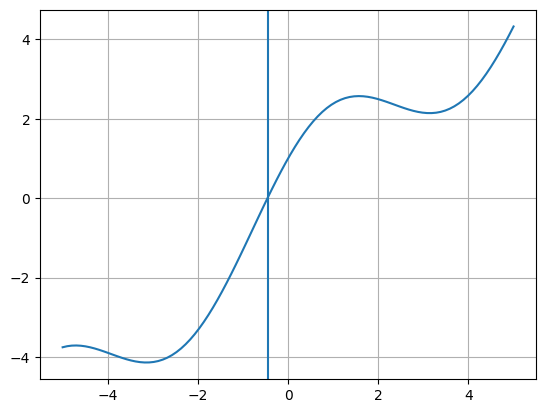

In [141]:
def test_g(x):
    return x + np.sin(x) + np.cos(x)

root = sekantMetode(test_g,4,5,0.1)
print(root[-1])
x=np.linspace(-5,5,100)
plt.figure("oppgave 1e")
plt.plot(x,test_g(x))
plt.axvline(root[-1],0,1)
plt.grid()
plt.show()

In [142]:
def BVP_solver(
        f,
        x_init : float,
        x_end : float,
        y_boundaries : tuple,
        b0 : float,
        b1 : float,
        tol : float = 0.001,
) -> tuple:
    
    def rungef(b,x_init=x_init,x_end=x_end,y_boundaries=y_boundaries,f=f,tol=1e-5):
        y_init=np.array((y_boundaries[0],b))
        x,y,n = RungeKutta32(x_init,x_end,y_init,f)
        return y[:,0][-1]-y_boundaries[1]
    
    b_iterations = sekantMetode(rungef,b0,b1,tol)
    y_init = np.array((y_boundaries[0],b_iterations[-1]))
    x,y,n = RungeKutta32(x_init,x_end,y_init,f)
    return x,y,n, b_iterations


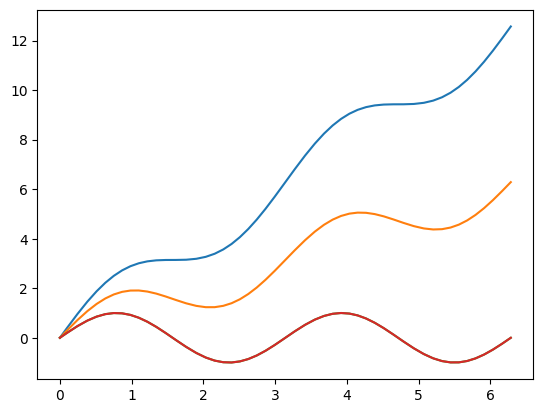

In [143]:
x_init = 0
x_end = 2*np.pi
y_boundaries=(0,0)
b0=4
b1=3


result = BVP_solver(diff_func_1a,x_init,x_end,y_boundaries,b0,b1, tol=1e-10)

plt.figure("BVP solution 1f")
for i in range(len(result[3])):  
    y_init=np.array((y_boundaries[0],result[3][i]))
    x,y,n = RungeKutta32(x_init,x_end,y_init,diff_func_1a) 
    
    plt.plot(x,y[:,0])
plt.show()



In [144]:
def diff_func_1g(
        x : float,
        y : np.ndarray[np.float64]
    )  -> np.ndarray[np.float64]:

    out=np.zeros_like(y)

    out[0]=y[1]
    out[1]=y[0] + np.sin(x)
    
    return out

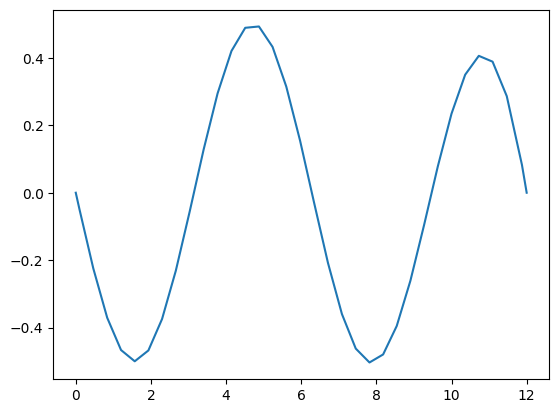

In [145]:
x_init = 0
x_end = 12
y_boundaries=(0,0)
b0=3
b1=2

result = BVP_solver(diff_func_1g,x_init,x_end,y_boundaries,b0,b1, tol=1e-10)


plt.figure("BVP solution 1g")
plt.plot(result[0],result[1][:,0])
plt.show()

In [146]:
def diff_func_1h(
        x : float,
        y : np.ndarray[np.float64]
    )  -> np.ndarray[np.float64]:

    out=np.zeros_like(y)

    out[0]=y[1]
    out[1]=y[0] + np.sin(x)
    
    return np.vstack(out)

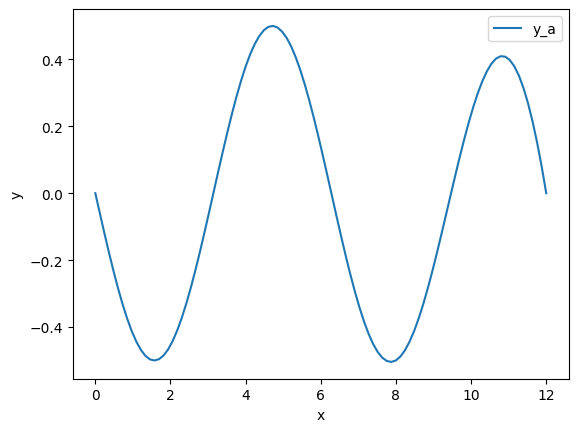

In [149]:
def y_bound(ya,yb):
    return np.array([ya[0],yb[0]])

from scipy.integrate import solve_bvp
x=np.linspace(x_init,x_end,10)
y_a = np.zeros((2, x.size))
y_a[0]=3

res_a = solve_bvp(diff_func_1h,y_bound,x,y_a)
plt.figure("BVP solution 1h")
x_plot = np.linspace(0, 12, 100)
y_plot_a = res_a.sol(x_plot)[0]

import matplotlib.pyplot as plt
plt.plot(x_plot, y_plot_a, label='y_a')
plt.legend()
plt.xlabel("x")
plt.ylabel("y")
plt.show()